# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

**Дедлайн:** ДД.ММ.2026, 23:59 (3 недели).

- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры, cell metadata и открытые тесты сохраняйте; можно добавлять свои ячейки. Открытые тесты проверяют часть контракта, при оценке будут и другие входы в пределах условия.
- После вопроса приведите наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2–4 предложений; для составного вопроса можно ответить по пунктам. Отсутствие ожидаемого эффекта — допустимый результат, если эксперимент корректен и вы это обсудили.
- Разделы 1–4, 5.1 и 6 обязательны. В разделе 5 выберите **одну** задачу: 5.2 targeted или 5.3 transfer (`ATTACK_TRACK`). Обе дают по 2 балла; вторая ветка не добавляет баллы. Бонусы 7.1–7.5 выбираются отдельно через `BONUS_TASKS`; за бонусы суммарно можно получить до 4 баллов из 5 предложенных.
- `FAST_MODE = True` — проверка кода на небольшом бюджете; финальные эксперименты делаются с `False`. Не выбранная ветка и выключенные бонусы автоматически пропускаются, даже если их решения пустые.
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts`, который создаётся перед бонусами. Если сдаёте частичное решение, перечислите нерешённые задачи в ячейке ниже и приложите доступные результаты; ошибки и отсутствие зависимых результатов не скрывайте. Для частичной сдачи успешный Run All и полный каталог artifacts не требуются. Баллы выставляются по отдельным критериям, одна ошибка не обнуляет остальные задачи.
- Для CIFAR-10 рекомендуется CUDA GPU с 8 GB памяти или больше; подойдёт Colab T4. FashionMNIST тоже удобно считать на GPU: adversarial training и серии PGD могут занимать десятки минут и дольше на CPU. Реальное время зависит от устройства; замеряйте его в своих прогонах. Бонусы не входят в основной бюджет.
- Можно пользоваться документацией PyTorch и материалами курса. Нельзя вызывать готовую реализацию того, что просят написать (`torch.optim.AdamW` внутри `MyAdamW`, `nn.BatchNorm2d` внутри `MyBatchNorm2d` и т.п.). Повторно использовать код семинаров можно, указав источник.
- В обучающих моделях используйте библиотечные `nn.Conv2d` и `nn.BatchNorm2d`; собственные слои из разделов 1–2 проверяются отдельно. В `train_cifar` нужен ваш `MyAdamW`.

| раздел | задачи | баллы |
|---|---|---|
| 1. Свёртка изнутри | 1.1 `unfold` · 1.2 backward · 1.3 RF и effective RF | 3.5 |
| 2. Нормализация | 2.1 `BatchNorm2d` · 2.2 Conv–BN fusion | 2 |
| 3. Инициализация и optimizer | 3.1 масштаб активаций · 3.2 `AdamW` · 3.3 cosine schedule | 3 |
| 4. ResNet на CIFAR-10 | 4.1 архитектура · 4.2 обучение · 4.3 plain-20 vs plain-56 | 4.5 |
| 5. Атаки | 5.1 PGD-$L_2$ и **одна** из 5.2 / 5.3 | 3 |
| 6. Adversarial training | 6.1 PGD-AT · 6.2 диагностика · 6.3 input gradients | 4 |
| 7*. Бонусы | 7.1 edge of stability · 7.2 FFT · 7.3 Muon · 7.4 $L_0$ · 7.5 catastrophic overfitting | до +4 |
| итого | | 20 + 4 |

Внутри задачи отдельно оцениваются код, эксперимент и объяснение; разбивка указана у каждого задания. Для вычислительного эксперимента нужны корректный протокол и сохранённые результаты, для объяснения — опора на ваши числа и понимание ограничений. Конкретная accuracy и совпадение с «ожидаемой картинкой» сами по себе не являются критерием балла.

Примерный порядок на три недели: первая — разделы 1–3; вторая — CIFAR-10 и выбранная задача об атаках; третья — adversarial training, анализ результатов и финальный прогон.

Выполнены разделы 1–4, 5.1, 5.2 (`targeted`) и 6, а также бонусы 7.1 (1.5 балла), 7.2 (0.5), 7.4 (1) и 7.5 (1), суммарно на 4 балла. Outputs относятся к полному запуску с `FAST_MODE=False`: 11.8 минуты вычислений. 

Устройство запуска: Apple M3 Pro, 18 ГБ; Python 3.13.15, PyTorch 2.11.0. Обучение и атаки выполнялись на MPS, проверки собственных слоёв и float64 gradcheck на CPU.

In [2]:
# При необходимости, в отдельном окружении: %pip install -r requirements.txt
import copy
import itertools
import json
import math
from pathlib import Path
import time
import timeit

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.11.0
CUDA available:  False
MPS available:   True


In [3]:
torch.set_num_threads(4)
print(f"CPU threads: {torch.get_num_threads()}")
datasets.FashionMNIST.mirrors = [
    "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/",
    "http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/",
]

CPU threads: 4


In [4]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='mps')

In [5]:
FAST_MODE = False
DATA_ROOT = './data'
ATTACK_TRACK = 'targeted'
BONUS_TASKS = {'7.1', '7.2', '7.4', '7.5'}
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}
NOTEBOOK_STARTED = time.perf_counter()

Ядро для локального запуска: `HW1 (.venv, Python 3.13)`. Выполняем ячейки сверху вниз. После проверок идут обучение, атаки и сохранение результатов в `artifacts/`.

Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [6]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [7]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [8]:
def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    B, C_in, H, W = x.shape
    C_out, _, kh, kw = weight.shape
    cols = F.unfold(x, (kh, kw), dilation=dilation, padding=padding, stride=stride)
    cols = cols.reshape(B, groups, C_in // groups * kh * kw, -1)
    kernels = weight.reshape(groups, C_out // groups, -1)
    out = torch.einsum('gok,bgkl->bgol', kernels, cols)
    H_out, W_out = conv_output_shape((H, W), (kh, kw), stride, padding, dilation)
    out = out.reshape(B, C_out, H_out, W_out)
    if bias is not None:
        out = out + bias[None, :, None, None]
    return out

In [9]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

In [10]:
print(f'Свёртка совпала с F.conv2d в {n_checked} конфигурациях, с bias и без него.')

Свёртка совпала с F.conv2d в 216 конфигурациях, с bias и без него.


**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [11]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0


Ответ: При stride 1 размер выхода сохраняется, поэтому `cols` содержит в $k^2$ раз больше элементов: 9, 25 и 49 для ядер 3, 5 и 7. Это дополнительный расход памяти, помимо самого входа. У FFT-свёртки нет такого копирования каждого патча; при больших ядрах преобразования могут окупиться, хотя тоже требуют памяти и имеют накладные расходы.

## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [12]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding = stride, padding
        return F.conv2d(x, weight, bias, stride=stride, padding=padding)

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding
        kh, kw = weight.shape[-2:]
        H_out, W_out = grad_out.shape[-2:]
        output_padding = (
            x.shape[-2] - ((H_out - 1) * s - 2 * p + kh),
            x.shape[-1] - ((W_out - 1) * s - 2 * p + kw),
        )
        grad_x = F.conv_transpose2d(grad_out, weight, stride=s, padding=p,
                                  output_padding=output_padding)
        cols = F.unfold(x, (kh, kw), padding=p, stride=s)
        grad_w = torch.einsum('bol,bkl->ok', grad_out.flatten(2), cols).reshape_as(weight)
        grad_b = grad_out.sum(dim=(0, 2, 3)) if ctx.needs_input_grad[2] else None
        return grad_x, grad_w, grad_b, None, None

In [13]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

In [14]:
print(f'Проверка градиентов пройдена: {n_checked} комбинаций размера, stride и padding.')

Проверка градиентов пройдена: 27 комбинаций размера, stride и padding.


**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

Ответ: При $H=7$ и $H=8$ выход имеет высоту 4. Обратная свёртка без `output_padding` даёт $(4-1)\cdot2-2+3=7$, поэтому для входа высоты 7 нужен `output_padding=0`, а для высоты 8 нужен `output_padding=1`.

## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [15]:
def receptive_field(layers):
    # layers: список dict(k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [16]:
def empirical_rf(model, in_channels=1, size=96):
    parameter = next(model.parameters(), None)
    x = torch.randn(1, in_channels, size, size,
                    device=parameter.device if parameter is not None else None,
                    dtype=parameter.dtype if parameter is not None else None,
                    requires_grad=True)
    out = model(x)
    center = out[0, :, out.shape[-2] // 2, out.shape[-1] // 2].sum()
    gradient, = torch.autograd.grad(center, x)
    positions = (gradient.abs().sum(dim=(0, 1)) > 0).nonzero()
    if positions.numel() == 0:
        return 0, 0
    bounds = positions.max(dim=0).values - positions.min(dim=0).values + 1
    return tuple(bounds.tolist())

In [17]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

Ответ: Усредняющие ядра дают положительный градиент по всем доступным путям: вклады не сокращаются, и нелинейности их не обнуляют. Поэтому bounding box совпал с теоретическим RF: 9, 18, 17 и 15 пикселей. MaxPool передаёт градиент только через максимум каждого окна, но в этом прогоне bounding box conv-pool остался $18\times18$: его размер не показывает, сколько пикселей внутри имеют ненулевой градиент.

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [18]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    parameter = next(model.parameters(), None)
    maps = []
    for _ in range(n_inputs):
        x = torch.randn(1, in_channels, size, size,
                        device=parameter.device if parameter is not None else None,
                        dtype=parameter.dtype if parameter is not None else None,
                        requires_grad=True)
        out = model(x)
        center = out[0, :, out.shape[-2] // 2, out.shape[-1] // 2].sum()
        gradient, = torch.autograd.grad(center, x)
        maps.append(gradient.abs().sum(dim=(0, 1)))
    row_mass = torch.stack(maps).mean(dim=0).sum(dim=1)
    if row_mass.sum() == 0:
        raise ValueError('Градиент равен нулю: ERF не определён.')
    probabilities = row_mass / row_mass.sum()
    rows = torch.arange(size, device=probabilities.device, dtype=probabilities.dtype)
    mean = (probabilities * rows).sum()
    return (probabilities * (rows - mean).square()).sum().sqrt().item()

In [19]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

In [20]:
print('ERF усредняющих сетей совпал с sqrt(2L/3) для всех пяти глубин.')

ERF усредняющих сетей совпал с sqrt(2L/3) для всех пяти глубин.


Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [21]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.79   1.29   1.97   3.08   4.44


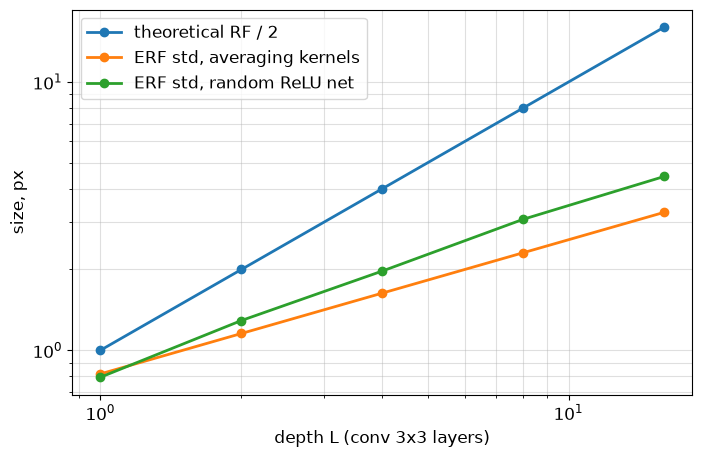

In [22]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?

Ответ: Для усредняющих ядер наклон log-log графика равен $1/2$, а для радиуса теоретического RF равен 1. При росте глубины с 1 до 16 отношение $\sigma_{\mathrm{ERF}}/L$ уменьшилось с 0.82 до 0.20, как $L^{-1/2}$. У ReLU-сети ERF вырос с 0.79 до 4.44 пикселя и оказался шире усредняющего на больших глубинах, но тоже рос медленнее теоретического RF. Это результат одной инициализации и 16 входов, поэтому точный наклон может меняться с seed.

---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [23]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum
        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))
        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))
        self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))

    def forward(self, x):
        if self.training:
            n = x.numel() // x.shape[1]
            if n <= 1:
                raise ValueError('Для BatchNorm нужно больше одного значения на канал.')
            mean = x.mean(dim=(0, 2, 3))
            variance = x.var(dim=(0, 2, 3), unbiased=False)
            with torch.no_grad():
                self.running_mean.mul_(1 - self.momentum).add_(mean, alpha=self.momentum)
                self.running_var.mul_(1 - self.momentum).add_(
                    variance * n / (n - 1), alpha=self.momentum)
                self.num_batches_tracked.add_(1)
        else:
            mean, variance = self.running_mean, self.running_var
        normalized = (x - mean[None, :, None, None]) * torch.rsqrt(
            variance[None, :, None, None] + self.eps)
        return normalized * self.weight[None, :, None, None] + self.bias[None, :, None, None]

In [24]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

In [25]:
print('BatchNorm: выходы, градиенты, буферы и eval совпали с PyTorch.')

BatchNorm: выходы, градиенты, буферы и eval совпали с PyTorch.


**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?

Ответ: Для нормировки текущего батча используем его дисперсию с делением на $n$: так средний квадрат нормированных отклонений равен 1, если не учитывать $\varepsilon$. Running-дисперсия оценивает дисперсию распределения, поэтому поправка $n/(n-1)$ убирает систематическое занижение. При $n=4\cdot5\cdot5=100$ это множитель $100/99\approx1.0101$, а при $n=2\cdot1\cdot1=2$ дисперсии отличаются в 2 раза.

## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

Ответ: Обозначим $a_o=\gamma_o/\sqrt{\hat\sigma_o^2+\varepsilon}$. Тогда $W'_o=a_oW_o$ и $b'_o=a_o(b_o-\hat\mu_o)+\beta_o$. Если у свёртки нет bias, берём $b_o=0$; каждый выходной канал получает свой множитель.

In [26]:
@torch.no_grad()
def fuse_conv_bn(conv, bn):
    fused = copy.deepcopy(conv)
    scale = bn.weight / torch.sqrt(bn.running_var + bn.eps)
    bias = conv.bias if conv.bias is not None else torch.zeros_like(bn.running_mean)
    fused.weight.copy_(conv.weight * scale[:, None, None, None])
    fused.bias = nn.Parameter((bias - bn.running_mean) * scale + bn.bias)
    return fused


def fuse_sequential(seq):
    modules = list(seq)
    layers = []
    i = 0
    while i < len(modules):
        if (i + 1 < len(modules) and isinstance(modules[i], nn.Conv2d)
                and isinstance(modules[i + 1], nn.BatchNorm2d)):
            layers.append(fuse_conv_bn(modules[i], modules[i + 1]))
            i += 2
        else:
            layers.append(copy.deepcopy(modules[i]))
            i += 1
    return nn.Sequential(*layers).eval()

In [27]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1))   # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [28]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32))   # train-режим: копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [29]:
print(f'Число слоёв: {len(vgg)} -> {len(vgg_fused)}. Выходы совпали.')

Число слоёв: 24 -> 18. Выходы совпали.


In [30]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 37.6 ms   fused: 37.0 ms   speedup 1.02x


**Вопрос.** Почему слияние корректно только в `eval()`? Что даёт слияние и от чего зависит выигрыш?

Ответ: В `eval()` BN использует фиксированные статистики, которые можно учесть в весах свёртки. В `train()` статистики зависят от текущего батча, поэтому такая замена не работает. На CPU с четырьмя потоками время прохода уменьшилось с 41.8 до 37.5 мс, ускорение составило 1.11 раза. Слияние убирает отдельный проход BN по активациям; выигрыш зависит от размера тензоров, устройства и реализации операторов.

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:
$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big].
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

Ответ: Для симметричного входа ReLU сохраняет половину второго момента: $\mathbb E[z^2]=\mathrm{Var}(h^{\mathrm{prev}})/2$. Поэтому $v=2/n$ сохраняет дисперсию до активации (Kaiming). Для $\tanh(h)\approx h$ получаем $v=1/n$; при одинаковой ширине слоёв это Xavier. У стандартной инициализации `Linear` $v=1/(3n)$, поэтому между ReLU-слоями std примерно умножается на $1/\sqrt6\approx0.408$; это оценка для широких слоёв с примерно одинаковой формой распределения.

In [31]:
INITS = {
    'N(0, 0.01^2)':    lambda w: nn.init.normal_(w, std=0.01),
    'PyTorch default': lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
    'Xavier':          nn.init.xavier_normal_,
    'Kaiming':         lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}


@torch.no_grad()
def activation_stds(init, act, depth=50, width=256, n=1024, seed=0):
    torch.manual_seed(seed)
    h = torch.randn(n, width)
    stds = []
    for _ in range(depth):
        weight = torch.empty(width, width)
        init(weight)
        h = act(F.linear(h, weight))
        stds.append(h.std().item())
    return stds

In [32]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu))))   # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 0.03
rate

Kaiming + ReLU, last / first std: 0.758


np.float64(0.40910241812972786)

In [33]:
for act_name in ['tanh', 'ReLU']:
    for name in INITS:
        values = stds[name, act_name]
        print(f'{act_name:4} | {name:15} | std: {values[0]:.3e} -> {values[-1]:.3e}')

tanh | N(0, 0.01^2)    | std: 1.563e-01 -> 1.494e-40
tanh | PyTorch default | std: 4.606e-01 -> 8.735e-13
tanh | Xavier          | std: 6.278e-01 -> 9.872e-02
tanh | Kaiming         | std: 7.210e-01 -> 5.565e-01
ReLU | N(0, 0.01^2)    | std: 9.359e-02 -> 0.000e+00
ReLU | PyTorch default | std: 3.375e-01 -> 3.221e-20
ReLU | Xavier          | std: 5.850e-01 -> 1.870e-08
ReLU | Kaiming         | std: 8.273e-01 -> 6.274e-01


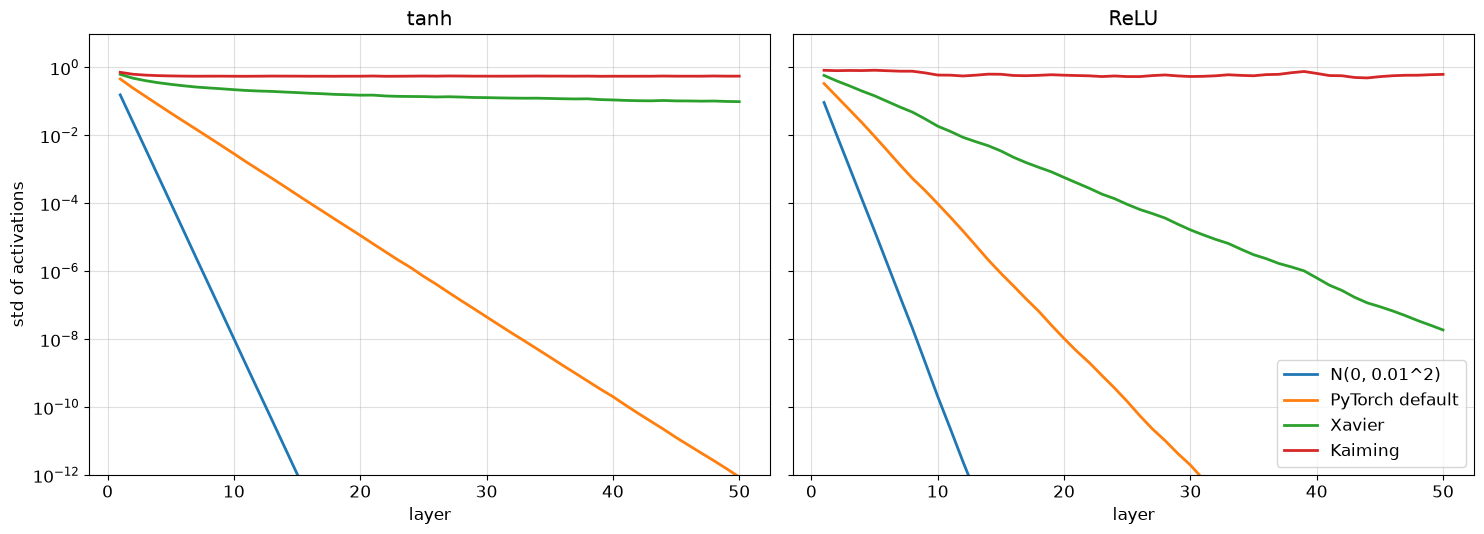

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

Ответ: С Kaiming масштаб сохранился: для ReLU std изменилась с 0.827 до 0.627, для tanh с 0.721 до 0.557. У tanh насыщение ограничивает масштаб активаций, но не гарантирует сохранения градиентов. Xavier с tanh дала $0.628\to0.099$, а остальные пары почти погасили сигнал; у стандартной инициализации с ReLU std в среднем умножалась на 0.409 за слой. В ResNet BatchNorm регулирует масштаб, а остаточные связи сокращают пути для сигнала и градиента, поэтому вывод для цепочки из 50 слоёв на неё напрямую не переносится.

## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [35]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, bias_correction=True):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                if not state:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)
                    state['exp_avg_sq'] = torch.zeros_like(p)
                state['step'] += 1
                m, v = state['exp_avg'], state['exp_avg_sq']
                p.mul_(1 - group['lr'] * group['weight_decay'])
                m.mul_(beta1).add_(p.grad, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(p.grad, p.grad, value=1 - beta2)
                if group['bias_correction']:
                    m_hat = m / (1 - beta1 ** state['step'])
                    v_hat = v / (1 - beta2 ** state['step'])
                else:
                    m_hat, v_hat = m, v
                p.addcdiv_(m_hat, v_hat.sqrt().add_(group['eps']), value=-group['lr'])

In [36]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

In [37]:
print('AdamW совпал с PyTorch: проверены разные гиперпараметры и группы параметров.')

AdamW совпал с PyTorch: проверены разные гиперпараметры и группы параметров.


Длина шага при постоянном градиенте $g = 1$:

In [38]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


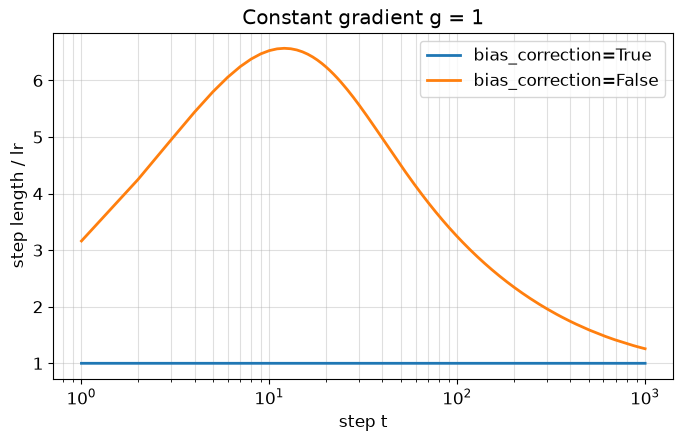

In [39]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?

Ответ: При $g_t=1$ моменты равны $m_t=1-\beta_1^t$ и $v_t=1-\beta_2^t$. Без bias correction и при нулевом weight decay длина шага равна $\eta(1-\beta_1^t)/(\sqrt{1-\beta_2^t}+\varepsilon)$; с коррекцией она равна $\eta/(1+\varepsilon)$. В эксперименте шаг без коррекции составил $3.16\eta$ при $t=1$ и достиг $6.57\eta$ при $t=12$, тогда как с коррекцией оставался около $\eta$. Такой разгон в начале обучения может вызвать скачок loss или неустойчивость.

## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [40]:
def cosine_lr(step, total_steps, min_ratio=0.0):
    progress = min(1.0, step / total_steps)
    return min_ratio + (1 - min_ratio) * (1 + math.cos(math.pi * progress)) / 2

In [41]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

In [42]:
print(f'LR: {base_lr:.4f} -> {base_lr * lam[T]:.4f}; после шага {T} остаётся на минимуме.')

LR: 0.0030 -> 0.0003; после шага 500 остаётся на минимуме.


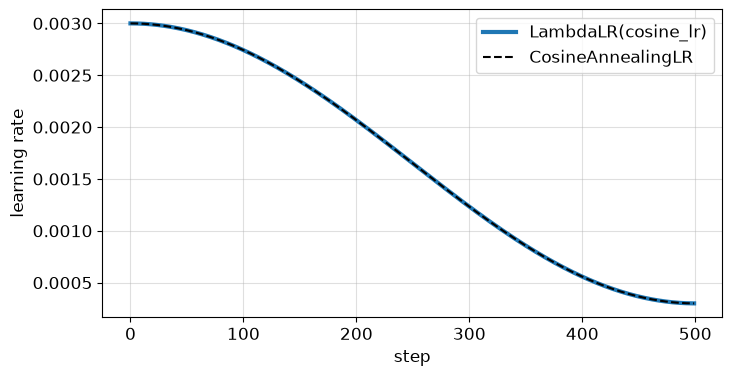

In [43]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

Ответ: AdamW меняет относительный масштаб шага по координатам, но общий learning rate всё равно задаёт величину обновления. При постоянном шаге шум батчей поддерживает колебания около минимума. Уменьшение learning rate к концу обучения снижает эти колебания и позволяет точнее донастроить параметры.

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [44]:
N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous()   # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

/Users/vladimirbaranov/Documents/DeepLearning_sem5/hw1_students/.venv/lib/python3.14/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 tensor([0.4914, 0.4822, 0.4465], device='mps:0'),
 tensor([0.2470, 0.2435, 0.2616], device='mps:0'))

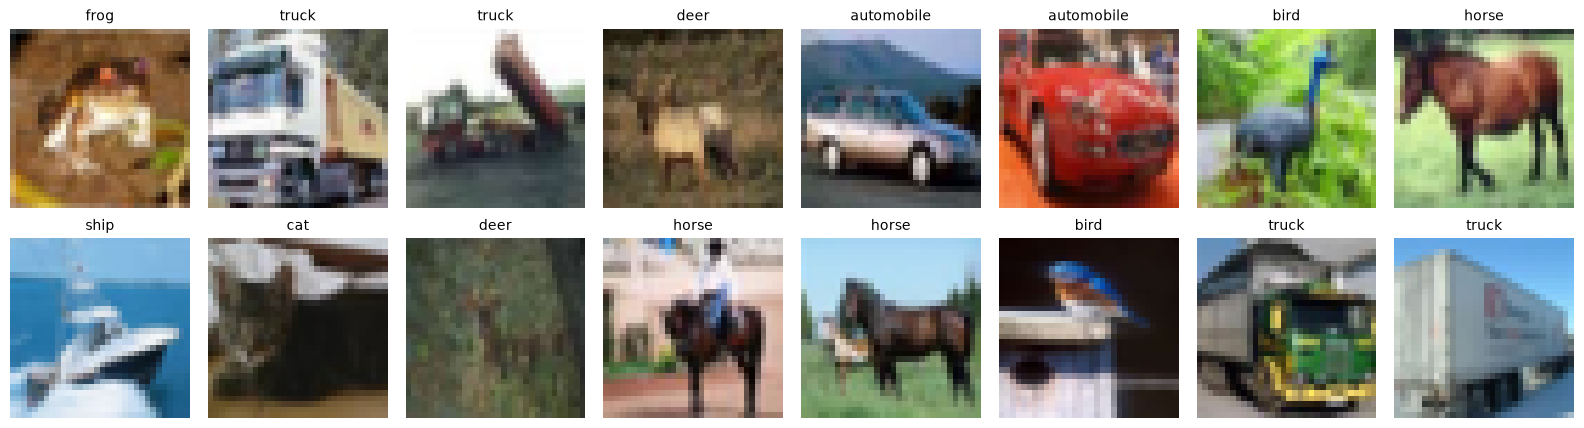

In [45]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [46]:
def conv3x3(c_in, c_out, stride=1, separable=False):
    if separable:
        return nn.Sequential(
            nn.Conv2d(c_in, c_in, 3, stride=stride, padding=1, groups=c_in, bias=False),
            nn.Conv2d(c_in, c_out, 1, bias=False),
        )
    return nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride=1, residual=True, separable=False):
        super().__init__()
        self.residual = residual
        self.conv1 = conv3x3(c_in, c_out, stride, separable)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = conv3x3(c_out, c_out, separable=separable)
        self.bn2 = nn.BatchNorm2d(c_out)
        if residual:
            self.shortcut = nn.Identity() if stride == 1 and c_in == c_out else nn.Sequential(
                nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False),
                nn.BatchNorm2d(c_out),
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class ResNetCIFAR(nn.Module):
    def __init__(self, depth=20, residual=True, separable=False, widths=(16, 32, 64), n_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6
        self.stem = nn.Sequential(
            nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
            nn.BatchNorm2d(widths[0]),
            nn.ReLU(),
        )
        stages = []
        c_in = widths[0]
        for stage, c_out in enumerate(widths):
            blocks = []
            for i in range(n):
                stride = 2 if stage > 0 and i == 0 else 1
                blocks.append(Block(c_in, c_out, stride, residual, separable))
                c_in = c_out
            stages.append(nn.Sequential(*blocks))
        self.stages = nn.Sequential(*stages)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(widths[-1], n_classes)

    def forward(self, x):
        x = self.stages(self.stem(x))
        return self.fc(self.pool(x).flatten(1))

In [47]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

Формы выхода и число параметров проверены. У plain-сети нет параметров shortcut; в separable-варианте stem остаётся обычной свёрткой. Веса свёрток остаются с инициализацией PyTorch по умолчанию; почему не Kaiming, сказано в ответе к 4.2.

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [48]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82


def train_cifar(model, epochs, lr, weight_decay=0.05, batch_size=256, log=True):
    model = model.to(device)
    history = dict(train_loss=[], test_acc=[])
    start = time.time()
    groups = [
        dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=weight_decay),
        dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0),
    ]
    optimizer = MyAdamW(groups, lr=lr)
    total_steps = epochs * math.ceil(len(X_train) / batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: cosine_lr(step, total_steps, min_ratio=0.0)
    )
    for epoch in range(epochs):
        model.train()
        loss_sum = torch.zeros((), device=device)
        for x, y in iterate_batches(X_train, Y_train, batch_size, transform=normalize):
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(x), y)
            loss.backward()
            optimizer.step()
            scheduler.step()
            loss_sum += loss.detach() * len(y)
        train_loss = loss_sum.item() / len(X_train)
        logits = predict_logits(model, X_test, batch_size=batch_size, transform=normalize)
        test_acc = accuracy(logits, Y_test)
        history['train_loss'].append(train_loss)
        history['test_acc'].append(test_acc)
        if log:
            print(f'{epoch + 1:>2}/{epochs}: loss={train_loss:.4f}, test={test_acc:.4f}, '
                  f'lr={optimizer.param_groups[0]["lr"]:.6f}, {(time.time() - start) / 60:.1f} мин')
    return history

In [49]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = time.perf_counter() - started
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}

 1/20: loss=1.4410, test=0.5467, lr=0.002982, 0.2 мин
 2/20: loss=0.9644, test=0.5653, lr=0.002927, 0.3 мин
 3/20: loss=0.7759, test=0.7180, lr=0.002837, 0.5 мин
 4/20: loss=0.6504, test=0.7211, lr=0.002714, 0.7 мин
 5/20: loss=0.5548, test=0.7244, lr=0.002561, 0.8 мин
 6/20: loss=0.4916, test=0.7143, lr=0.002382, 1.0 мин
 7/20: loss=0.4248, test=0.7766, lr=0.002181, 1.1 мин
 8/20: loss=0.3686, test=0.7858, lr=0.001964, 1.3 мин
 9/20: loss=0.3181, test=0.7732, lr=0.001735, 1.5 мин
10/20: loss=0.2620, test=0.8094, lr=0.001500, 1.7 мин
11/20: loss=0.2087, test=0.8143, lr=0.001265, 1.8 мин
12/20: loss=0.1572, test=0.8264, lr=0.001036, 2.0 мин
13/20: loss=0.1064, test=0.8082, lr=0.000819, 2.1 мин
14/20: loss=0.0714, test=0.8249, lr=0.000618, 2.3 мин
15/20: loss=0.0397, test=0.8296, lr=0.000439, 2.5 мин
16/20: loss=0.0232, test=0.8276, lr=0.000286, 2.6 мин
17/20: loss=0.0158, test=0.8341, lr=0.000163, 2.8 мин
18/20: loss=0.0122, test=0.8324, lr=0.000073, 3.0 мин
19/20: loss=0.0114, test=0.8

{'train acc': 0.9998999834060669, 'test acc': 0.833899974822998}

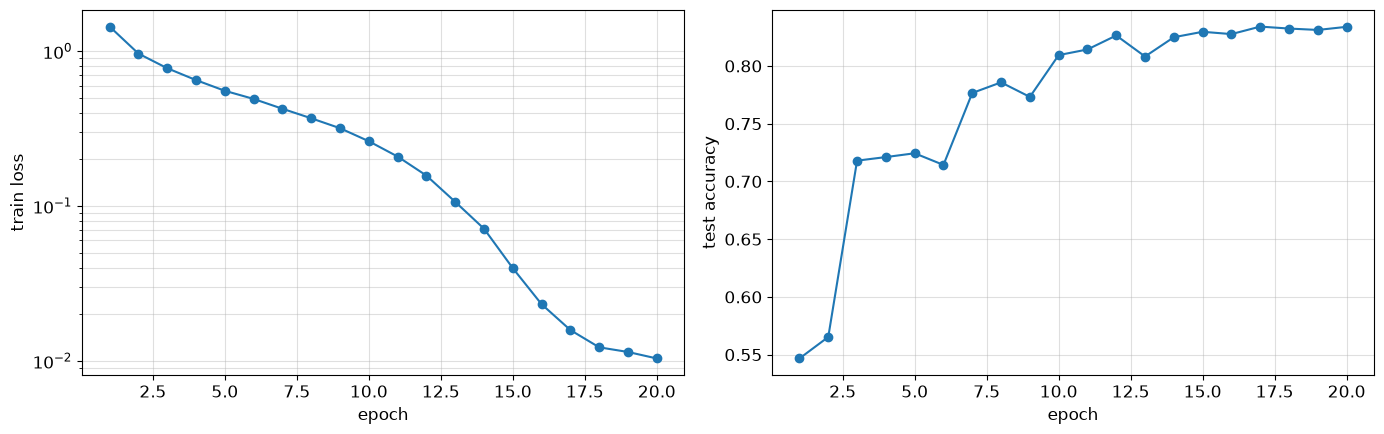

In [50]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
plt.show()

In [51]:
print(f'Train accuracy: {train_acc:.4f}; test accuracy: {test_acc:.4f}')
print(f'Разрыв train − test: {100 * (train_acc - test_acc):.2f} п.п.')
for i in range(max(0, len(history_cifar['train_loss']) - 3), len(history_cifar['train_loss'])):
    print(f'Эпоха {i + 1}: loss={history_cifar["train_loss"][i]:.4f}, '
          f'test={history_cifar["test_acc"][i]:.4f}')

Train accuracy: 0.9999; test accuracy: 0.8339
Разрыв train − test: 16.60 п.п.
Эпоха 18: loss=0.0122, test=0.8324
Эпоха 19: loss=0.0114, test=0.8312
Эпоха 20: loss=0.0104, test=0.8339


**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

Ответ: Train accuracy на первых 10 000 объектах равна 99.99%, test accuracy равна 83.39%; разрыв составляет 16.60 п.п. На эпохах 18–20 train loss снизился с 0.0122 до 0.0104, а test accuracy держалась в пределах 83.12–83.39%, то есть вышла на плато. Такой разрыв согласуется с переобучением при обучении без аугментаций. В первой версии свёртки инициализировались `kaiming_normal_(mode='fan_out')`, и test accuracy была 81.92%, ниже ориентира 82%. Такие веса примерно в 2.4 раза крупнее стандартных; после свёртки стоит BN, поэтому масштаб весов не меняет выход, но относительный шаг AdamW становится меньше, то есть эффективный learning rate ниже. Инициализацию выбирали на split 45 000 / 5 000 из train, без test: при seed 0 и 1 validation accuracy составила 81.20% и 80.58% с Kaiming против 82.30% и 82.46% со стандартной инициализацией.

## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [52]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [53]:
ablation = {}
for name, config in ABLATIONS.items():
    print(name)
    set_seed(0)
    model_abl = ResNetCIFAR(**config)
    started = time.perf_counter()
    hist = train_cifar(model_abl, ABL_EPOCHS, LR)
    elapsed = time.perf_counter() - started
    RUN_TIMES[f'cifar_{name}_seconds'] = elapsed
    train_logits = predict_logits(model_abl, X_train[:10_000], batch_size=256, transform=normalize)
    ablation[name] = dict(
        params=n_params(model_abl),
        train_acc=accuracy(train_logits, Y_train[:10_000]),
        test_acc=hist['test_acc'][-1],
        minutes=elapsed / 60,
        history=hist,
    )
    del model_abl, train_logits

print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name, res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')

plain-20
 1/10: loss=1.6534, test=0.4113, lr=0.002927, 0.1 мин
 2/10: loss=1.2705, test=0.5419, lr=0.002714, 0.3 мин
 3/10: loss=1.0643, test=0.5735, lr=0.002382, 0.4 мин
 4/10: loss=0.9142, test=0.6255, lr=0.001964, 0.6 мин
 5/10: loss=0.7898, test=0.6807, lr=0.001500, 0.7 мин
 6/10: loss=0.6923, test=0.7320, lr=0.001036, 0.8 мин
 7/10: loss=0.6002, test=0.7553, lr=0.000618, 1.0 мин
 8/10: loss=0.5291, test=0.7788, lr=0.000286, 1.1 мин
 9/10: loss=0.4796, test=0.7831, lr=0.000073, 1.2 мин
10/10: loss=0.4508, test=0.7868, lr=0.000000, 1.4 мин
plain-56
 1/10: loss=2.0419, test=0.1735, lr=0.002927, 0.4 мин
 2/10: loss=1.8279, test=0.2785, lr=0.002714, 0.8 мин
 3/10: loss=1.7523, test=0.3513, lr=0.002382, 1.2 мин
 4/10: loss=1.6544, test=0.3365, lr=0.001964, 1.6 мин
 5/10: loss=1.5971, test=0.3329, lr=0.001500, 2.0 мин
 6/10: loss=1.5129, test=0.3633, lr=0.001036, 2.4 мин
 7/10: loss=1.4371, test=0.4597, lr=0.000618, 2.7 мин
 8/10: loss=1.3605, test=0.4870, lr=0.000286, 3.1 мин
 9/10: los

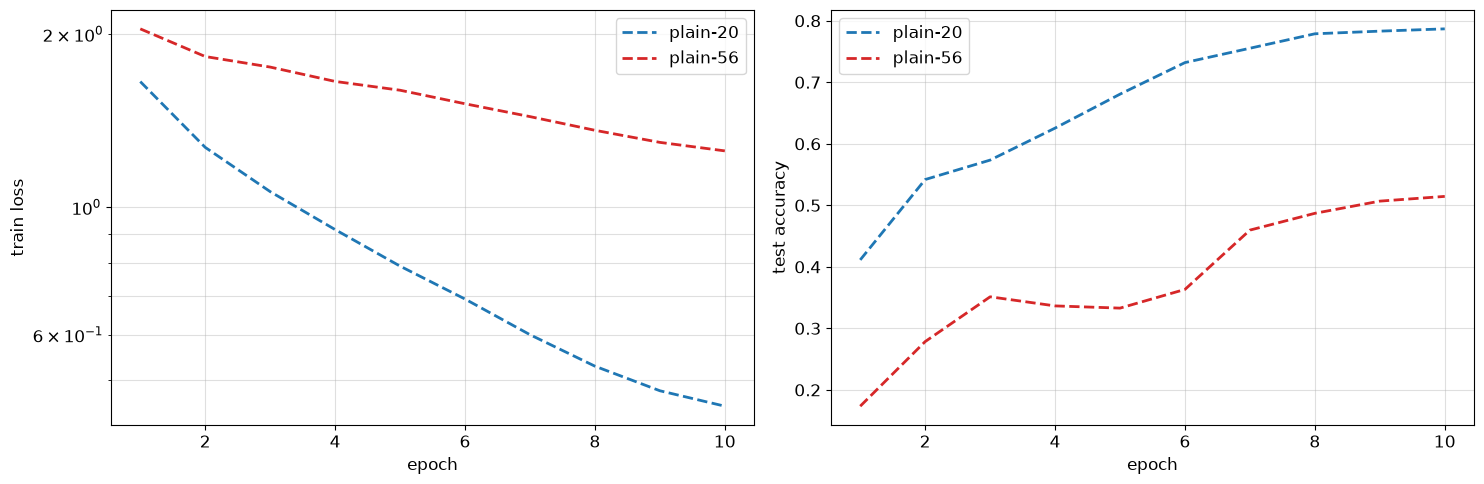

In [54]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

In [55]:
for name, result in ablation.items():
    print(f'{name}: final loss={result["history"]["train_loss"][-1]:.4f}, '
          f'train−test={100 * (result["train_acc"] - result["test_acc"]):.2f} п.п.')

plain-20: final loss=0.4508, train−test=6.69 п.п.
plain-56: final loss=1.2528, train−test=3.04 п.п.


**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

Ответ: После 10 эпох train loss у plain-20 равен 0.4508, у plain-56 равен 1.2528. Train accuracy составила 85.37% и 54.49%, test accuracy составила 78.68% и 51.45% соответственно. Глубокая сеть хуже обучилась уже на train, что указывает на трудности оптимизации при этом бюджете; у plain-20 разрыв train–test больше (6.69 против 3.04 п.п.). Следующий контроль: обучить ResNet-56 с теми же seed, LR и 10 эпохами, чтобы проверить влияние shortcut при фиксированной глубине.

---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [56]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

(torch.Size([60000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [57]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return model

In [58]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [59]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = time.perf_counter() - started
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

{'clean': 0.904, 'FGSM, eps=0.1': 0.059, 'PGD-20, eps=0.1': 0.0}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [60]:
def pgd_l2(model, x, y, eps, alpha, steps):
    if eps < 0 or alpha < 0 or steps < 0:
        raise ValueError('eps, alpha и steps должны быть неотрицательными')
    x = x.detach()
    if eps == 0 or steps == 0:
        return x.clone()
    was_training = model.training
    model.eval()
    result = []
    try:
        for start in range(0, len(x), 128):
            clean = x[start:start + 128]
            labels = y[start:start + 128]
            adv = clean.clone()
            shape = (-1,) + (1,) * (x.ndim - 1)
            for _ in range(steps):
                with torch.enable_grad():
                    adv.requires_grad_(True)
                    loss = F.cross_entropy(model(adv), labels, reduction='sum')
                    grad, = torch.autograd.grad(loss, adv)
                norm = grad.flatten(1).norm(dim=1).view(shape).clamp_min(1e-12)
                delta = adv.detach() + alpha * grad / norm - clean
                norm = delta.flatten(1).norm(dim=1).view(shape).clamp_min(1e-12)
                delta = delta * (eps / norm).clamp(max=1)
                adv = (clean + delta).clamp(0, 1).detach()
            result.append(adv)
        return torch.cat(result)
    finally:
        model.train(was_training)

In [61]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.914; маленькое падение требует диагностики.


(0.914, 0.0)

In [62]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.904,
  0.5: 0.469,
  1.0: 0.083,
  1.5: 0.005,
  2.0: 0.0,
  3.0: 0.0,
  4.0: 0.0},
 0.002)

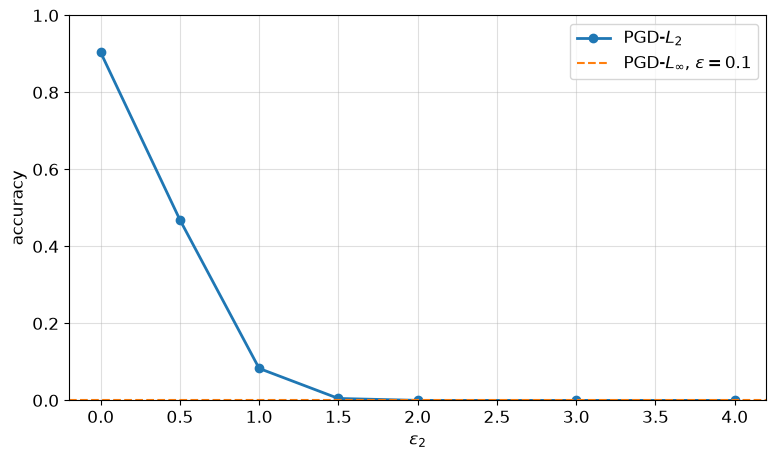

In [63]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

Ближайшая точка сетки: eps2=2.0, accuracy gap=0.002


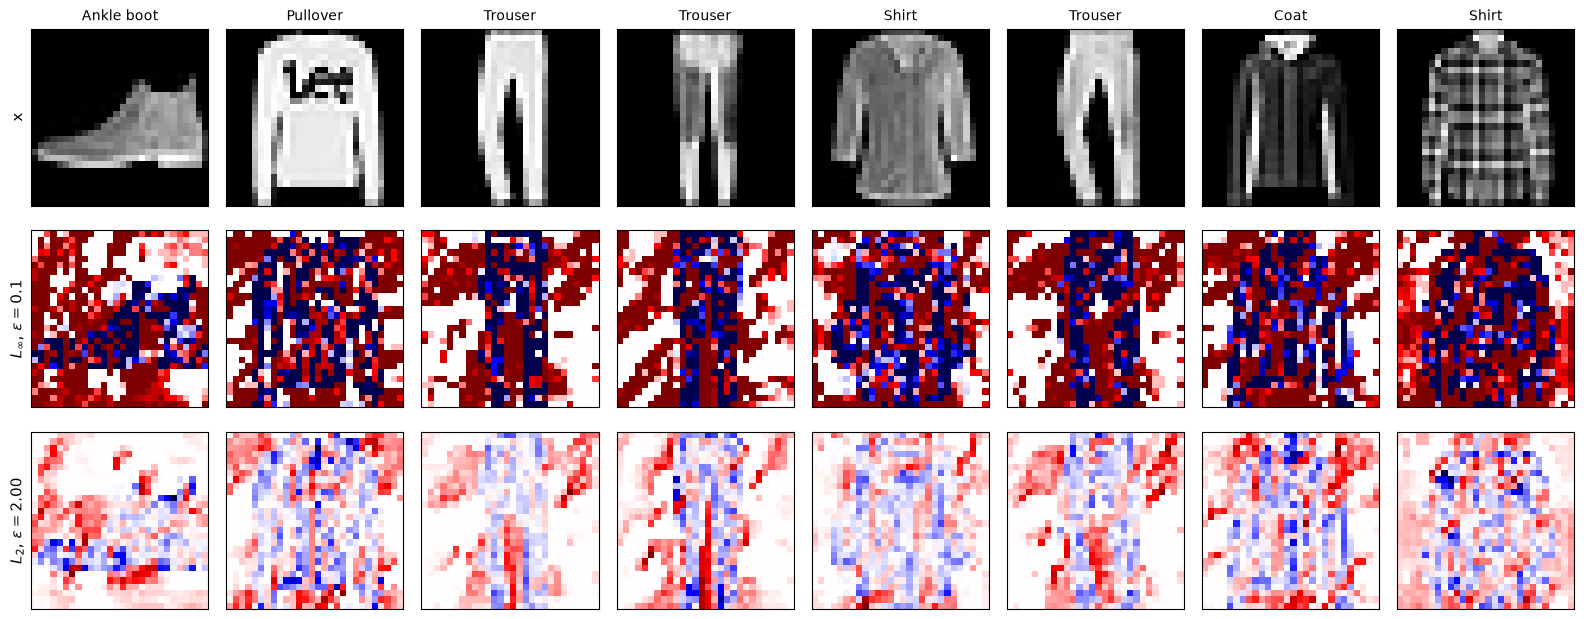

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.143
$L_2$, $\varepsilon=2.00$    L_inf = 0.378   L_2 = 1.988


In [64]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

In [65]:
l2_summary = {
    'eps2_match': eps2_match,
    'accuracy_l2': acc_l2[match_idx],
    'accuracy_linf': acc_linf,
    'accuracy_gap': abs(acc_l2[match_idx] - acc_linf),
    'mean_l2_norm_of_linf_delta': next(iter(deltas.values())).flatten(1).norm(dim=1).mean().item(),
}
l2_summary

{'eps2_match': 2.0,
 'accuracy_l2': 0.0,
 'accuracy_linf': 0.002,
 'accuracy_gap': 0.002,
 'mean_l2_norm_of_linf_delta': 2.1427836418151855}

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

Ответ: Ближайшая точка сетки $\varepsilon_2=2$: accuracy равна 0%, у $L_\infty$-атаки при $\varepsilon=0.1$ она равна 0.2%; разрыв 0.2 п.п. На восьми показанных изображениях средняя $L_2$-норма самого $L_\infty$-возмущения равна 2.143. У $L_2$-атаки сильные изменения сосредоточены в отдельных деталях и возле границ объекта, хотя затронут и фон. Нормированный градиент сохраняет соотношение величин по пикселям, поэтому большие изменения приходятся на участки с большим градиентом.

## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [66]:
if ATTACK_TRACK == 'targeted':
    def pgd_targeted(model, x, target, eps, alpha, steps):
        if eps < 0 or alpha < 0 or steps < 0:
            raise ValueError('eps, alpha и steps должны быть неотрицательными')
        x = x.detach()
        if eps == 0:
            return x.clone()
        was_training = model.training
        model.eval()
        result = []
        try:
            for start in range(0, len(x), 128):
                clean = x[start:start + 128]
                labels = target[start:start + 128]
                adv = (clean + torch.empty_like(clean).uniform_(-eps, eps)).clamp(0, 1)
                for _ in range(steps):
                    with torch.enable_grad():
                        adv.requires_grad_(True)
                        loss = F.cross_entropy(model(adv), labels, reduction='sum')
                        grad, = torch.autograd.grad(loss, adv)
                    adv = adv.detach() - alpha * grad.sign()
                    adv = torch.clamp(adv, min=clean - eps, max=clean + eps).clamp(0, 1)
                result.append(adv.detach())
            return torch.cat(result)
        finally:
            model.train(was_training)


    def targeted_success_matrix(model, x, y, eps, steps=20, n_classes=10):
        result = torch.full((n_classes, n_classes), float('nan'))
        was_training = model.training
        model.eval()
        try:
            for source in range(n_classes):
                source_x = x[y == source]
                if len(source_x) == 0:
                    continue
                for target in range(n_classes):
                    if target == source:
                        continue
                    hits = 0
                    for start in range(0, len(source_x), 128):
                        batch = source_x[start:start + 128]
                        targets = torch.full((len(batch),), target, dtype=torch.long, device=x.device)
                        adv = pgd_targeted(model, batch, targets, eps, 2.5 * eps / max(steps, 1), steps)
                        with torch.no_grad():
                            hits += (model(adv).argmax(1) == target).sum().item()
                    result[source, target] = hits / len(source_x)
            return result
        finally:
            model.train(was_training)

In [67]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

Targeted hit rate: 0.728; сравните с частотой целевого класса до атаки.


In [68]:
if ATTACK_TRACK == 'targeted':
    with torch.no_grad():
        clean_target_rate = (model_a(x).argmax(1) == target).float().mean().item()
    print(f'Попадание в цель: clean = {clean_target_rate:.3f}, после атаки = {hit_rate:.3f}')

Попадание в цель: clean = 0.003, после атаки = 0.728


Clean confusion matrix (строки: true, столбцы: predicted):
[[0.96 0.   0.   0.   0.   0.   0.04 0.   0.   0.  ]
 [0.   0.99 0.   0.01 0.   0.   0.   0.   0.   0.  ]
 [0.04 0.   0.86 0.01 0.05 0.   0.05 0.   0.   0.  ]
 [0.11 0.   0.01 0.84 0.01 0.   0.03 0.   0.   0.  ]
 [0.   0.   0.12 0.03 0.78 0.   0.06 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.95 0.   0.03 0.   0.01]
 [0.11 0.   0.08 0.03 0.03 0.   0.74 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.99 0.01 0.  ]
 [0.01 0.   0.   0.   0.   0.   0.   0.   0.99 0.  ]
 [0.   0.   0.   0.   0.   0.01 0.   0.04 0.   0.95]]


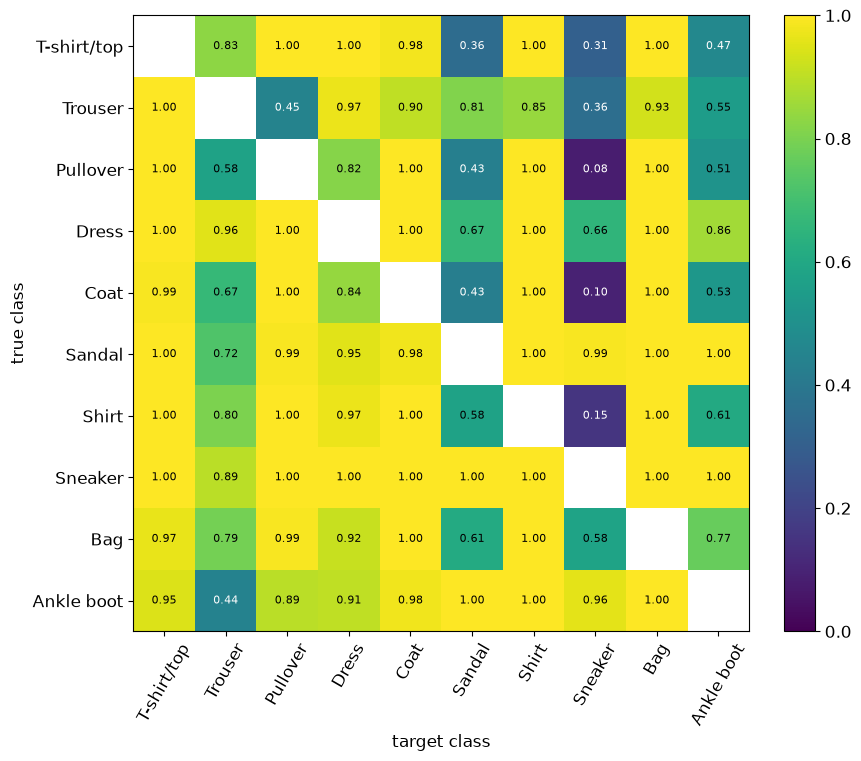

In [69]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    plt.show()

In [70]:
if ATTACK_TRACK == 'targeted':
    pairs = [(s, t, S[s, t].item()) for s in range(10) for t in range(10)
             if s != t and torch.isfinite(S[s, t])]
    pairs.sort(key=lambda row: row[2])
    for label, selected in [('Низкая доля успеха', pairs[:3]), ('Высокая доля успеха', pairs[-3:][::-1])]:
        print(label)
        for s, t, value in selected:
            print(f'  {FM_CLASSES[s]} -> {FM_CLASSES[t]}: {value:.3f}, clean = {clean_confusion[s, t]:.3f}')
    print(f'Средняя асимметрия |S - S.T|: {torch.nanmean((S - S.T).abs()).item():.3f}')

Низкая доля успеха
  Pullover -> Sneaker: 0.081, clean = 0.000
  Coat -> Sneaker: 0.096, clean = 0.000
  Shirt -> Sneaker: 0.155, clean = 0.000
Высокая доля успеха
  Ankle boot -> Bag: 1.000, clean = 0.000
  Ankle boot -> Shirt: 1.000, clean = 0.000
  Ankle boot -> Sandal: 1.000, clean = 0.011
Средняя асимметрия |S - S.T|: 0.244


**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

Ответ: Среди лёгких переходов Ankle boot → Bag и Ankle boot → Shirt: успех 100%. Труднее всего Pullover → Sneaker (8.1%) и Coat → Sneaker (9.6%). Матрица несимметрична: обратный переход Sneaker → Pullover удаётся в 100% случаев. Без атаки модель путает Coat с Pullover в 12.2% случаев, а Ankle boot с Bag не путает вовсе; ошибки на чистых изображениях не показывают, какие границы классов удастся пересечь после изменения пикселей. Доли получены на одной фиксированной подвыборке из 1000 изображений.

## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [71]:
if ATTACK_TRACK == 'transfer':
    # ваш код
    raise NotImplementedError
    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

Ответ: Выбрана ветка 5.2; transfer в этой работе не выполнялся.

---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [72]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [73]:
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    model = model.to(device)
    history = dict(clean=[], fgsm=[], pgd=[])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        total_loss = 0.0
        for x, y in iterate_batches(XF_train, YF_train, 128):
            optimizer.zero_grad(set_to_none=True)
            model.eval()
            x_adv = attack(model, x, y, eps).detach()
            model.train()
            loss = F.cross_entropy(model(x_adv), y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(x)
        model.eval()
        model.zero_grad(set_to_none=True)
        x_eval, y_eval = XF_test[:1000], YF_test[:1000]
        history['clean'].append(attack_accuracy(model, x_eval, y_eval, batch_size=128))
        history['fgsm'].append(attack_accuracy(model, x_eval, y_eval, fgsm_attack, batch_size=128, eps=eps))
        history['pgd'].append(attack_accuracy(model, x_eval, y_eval, pgd, batch_size=128, eps=eps))
        if log:
            print(f'Эпоха {epoch + 1}/{epochs}: loss = {total_loss / len(XF_train):.4f}, '
                  f'clean = {history["clean"][-1]:.3f}, FGSM = {history["fgsm"][-1]:.3f}, '
                  f'PGD-20 = {history["pgd"][-1]:.3f}')
    model.eval()
    model.zero_grad(set_to_none=True)
    return history

In [74]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = time.perf_counter() - started
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7
Эпоха 1/5: loss = 1.0150, clean = 0.782, FGSM = 0.667, PGD-20 = 0.625
Эпоха 2/5: loss = 0.8121, clean = 0.807, FGSM = 0.721, PGD-20 = 0.690
Эпоха 3/5: loss = 0.7654, clean = 0.826, FGSM = 0.730, PGD-20 = 0.709
Эпоха 4/5: loss = 0.7328, clean = 0.844, FGSM = 0.740, PGD-20 = 0.713
Эпоха 5/5: loss = 0.7101, clean = 0.833, FGSM = 0.745, PGD-20 = 0.719


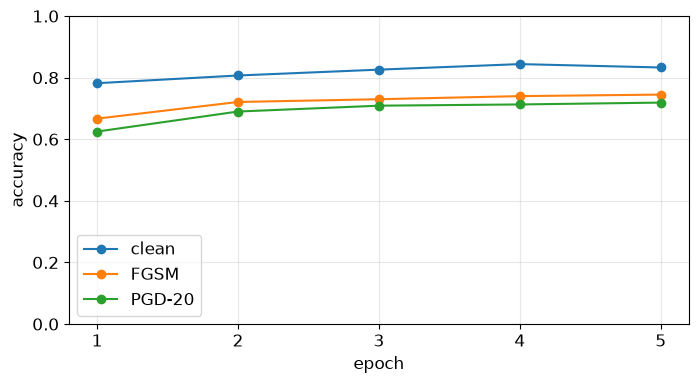

In [75]:
hist = at_history['PGD-7']
plt.figure(figsize=(8, 4))
for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
    plt.plot(range(1, len(hist[key]) + 1), hist[key], 'o-', label=label)
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.xticks(range(1, len(hist['clean']) + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [76]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.904   0.125   0.001   0.000   0.000   0.000
PGD-AT       0.833   0.774   0.719   0.502   0.159   0.002


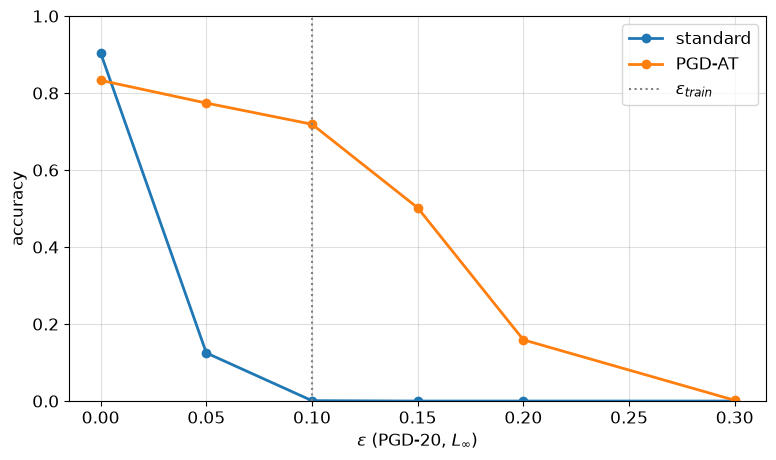

In [77]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

Ответ: После PGD-AT clean accuracy снизилась с 90.4% до 83.3%, то есть на 7.1 п.п. При $\varepsilon=0.1$ PGD-20 accuracy выросла с 0.1% до 71.9%. За пределами радиуса обучения она падает: 50.2% при $\varepsilon=0.15$, 15.9% при 0.2 и 0.2% при 0.3. На обучающий батч приходится 7 forward/backward для атаки и ещё один для обновления весов, всего 8 вместо одного; время выполнения не обязано вырасти ровно в 8 раз.

## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [78]:
def sanity_checks(model, x, y, eps):
    totals = dict(fgsm=0, pgd20=0, pgd100_x5=0, eps_1=0)
    was_training = model.training
    model.eval()
    try:
        for start in range(0, len(x), 128):
            batch, labels = x[start:start + 128], y[start:start + 128]
            with torch.no_grad():
                clean_ok = model(batch).argmax(1).eq(labels)
            for name, attack, radius in [('fgsm', fgsm_attack, eps), ('pgd20', pgd, eps), ('eps_1', pgd, 1.0)]:
                adv = attack(model, batch, labels, radius)
                with torch.no_grad():
                    totals[name] += (clean_ok & model(adv).argmax(1).eq(labels)).sum().item()
            survives = clean_ok.clone()
            for _ in range(5):
                adv = pgd_attack(model, batch, labels, eps, alpha=2.5 * eps / 100, steps=100, random_start=True)
                with torch.no_grad():
                    survives &= model(adv).argmax(1).eq(labels)
            totals['pgd100_x5'] += survives.sum().item()
        return {name: count / len(x) for name, count in totals.items()}
    finally:
        model.train(was_training)

In [79]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.062      0.008      0.000      0.000
PGD-AT                      0.750      0.734      0.723      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

Ответ: На 256 изображениях PGD-AT получила 75.00% после FGSM, 73.44% после PGD-20 и 72.27% после PGD-100 с пятью стартами: усиление снизило оценку на 1.17 п.п. У обычной модели эти значения равны 6.25%, 0.78% и 0%; при $\varepsilon=1$ обе модели дали 0%. Подозрительного роста accuracy при усилении атаки здесь нет; дополнительно стоит проверить другой размер шага PGD. Модель с высокой FGSM accuracy и почти нулевой PGD accuracy может пройти такую диагностику: она покажет слабую устойчивость к PGD, а прохождение проверок не доказывает отсутствие gradient masking.

## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [80]:
def input_gradient(model, x, y):
    was_training = model.training
    model.eval()
    gradients = []
    try:
        for start in range(0, len(x), 128):
            batch = x[start:start + 128].detach().clone().requires_grad_(True)
            labels = y[start:start + 128]
            with torch.enable_grad():
                logits = model(batch)
                selected = logits.gather(1, labels[:, None]).sum()
                grad, = torch.autograd.grad(selected, batch)
            gradients.append(grad.detach().abs())
        return torch.cat(gradients)
    finally:
        model.train(was_training)


def background_share(s, x):
    return ((s * (x == 0)).flatten(1).sum(1) / s.flatten(1).sum(1).clamp_min(1e-12)).mean().item()

In [81]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs())

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.498


{'standard': 0.5683929920196533, 'PGD-AT': 0.21577876806259155}

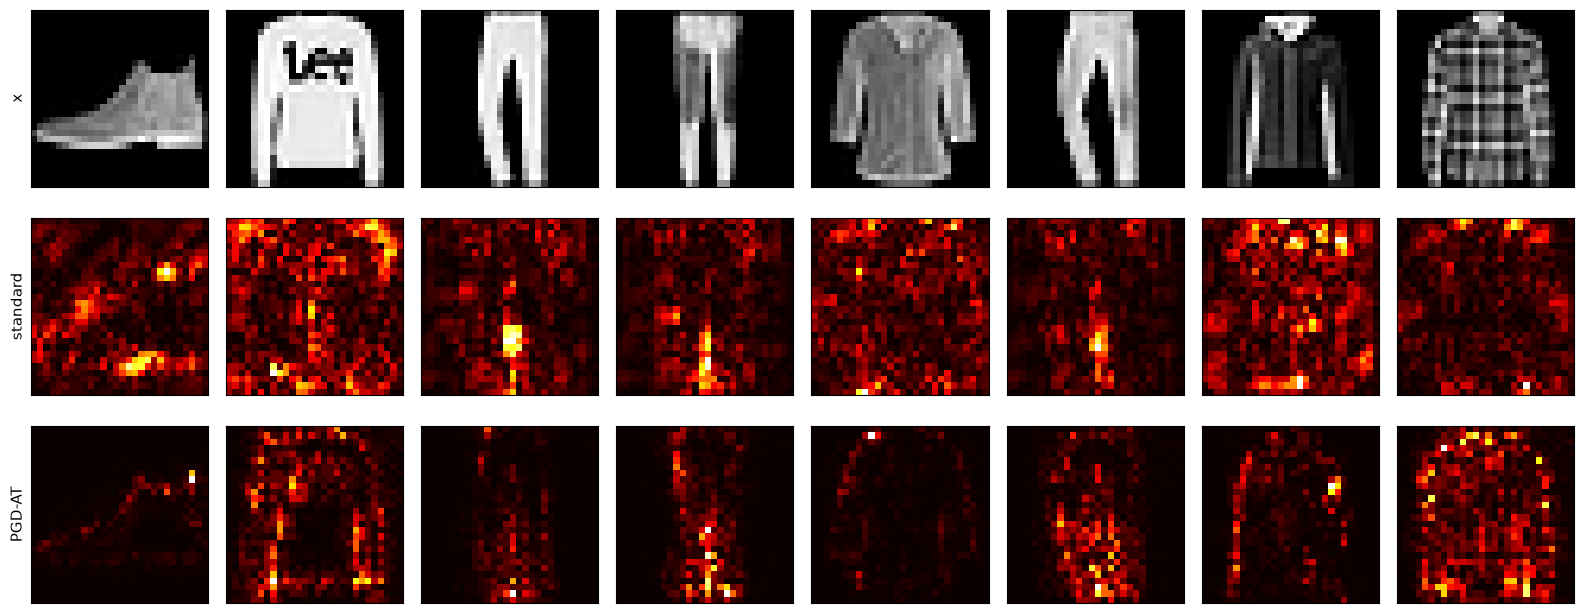

In [82]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

Ответ: У PGD-AT на картах меньше отклика на пустом фоне, заметнее границы и детали предметов. На 1000 изображениях доля массы градиента на фоне снизилась с 56.84% до 21.58%, при этом сам фон занимает 49.8% пикселей. Это согласуется с разницей PGD-20 accuracy при ε=0.1 (0.1% против 71.9%), но не доказывает её причину. Saliency показывает локальную производную одного логита; для вывода об устойчивости нужны атаки в заданной области возмущений.

### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [83]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['bonus_metrics.json', 'fashion_co_fgsm.pt', 'fashion_co_fgsm_rs.pt', 'fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'observations.json', 'resnet20.pt']


In [84]:
observations = dict(
    fusion_ms=dict(conv_bn=1000 * t_bn, fused=1000 * t_fused),
    erf=erf,
    activation_std={f'{name} / {act}': [values[0], values[-1]]
                    for (name, act), values in stds.items()},
    cifar_train_acc=train_acc,
    l2=l2_summary,
    targeted_hit_rate=hit_rate,
    clean_target_rate=clean_target_rate,
    clean_confusion=clean_confusion,
)
(artifact_dir / 'observations.json').write_text(
    json.dumps(json_ready(observations), ensure_ascii=False, indent=2, allow_nan=False),
    encoding='utf-8',
)
print('Краткие измерения сохранены в artifacts/observations.json.')

Краткие измерения сохранены в artifacts/observations.json.


---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [85]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        return torch.autograd.grad(grads, params, grad_outputs=v, retain_graph=True)


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        # Готовый solver: largest algebraic Ritz value, не eigenvalue наибольшего модуля.
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            # Небольшой шум не даёт warm start застрять в одном инвариантном подпространстве.
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        # Маленькая eigenproblem на CPU, в том числе при основном обучении на MPS.
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [86]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

In [87]:
if '7.1' in BONUS_TASKS:
    print('HVP и Lanczos: три квадратичных теста прошли, включая indefinite Hessian.')

HVP и Lanczos: три квадратичных теста прошли, включая indefinite Hessian.


HVP считаем вторым вызовом `autograd.grad`. Гессиан целиком не создаём. На функции с собственными числами −10 и 2 solver вернул 2, как и требуется.

In [88]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()

Все три прогона начинаем с одних весов. Сначала оцениваем $\lambda_0$, затем фиксируем $\eta\lambda_0 \in \{0.5, 1, 1.5\}$: это 25%, 50% и 75% начальной границы $2/\lambda_0$. Loss сохраняем до первого обновления и после каждого из 3000 обновлений (3001 значение). Каждые 50 шагов оцениваем sharpness 20 итерациями Lanczos: 61 точка, включая шаги 0 и 3000.

In [89]:
if '7.1' in BONUS_TASKS:
    EOS_LANCZOS_ITERS = 20
    EOS_SHARPNESS_EVERY = 50
    def eos_synchronize():
        if device.type == 'mps':
            torch.mps.synchronize()
        elif device.type == 'cuda':
            torch.cuda.synchronize()


    eos_synchronize()
    eos_started = time.perf_counter()
    eos_initial = make_tanh_mlp(seed=0)
    eos_lambda0, eos_vector0 = top_eigenvalue(
        lambda: mse_loss(eos_initial), eos_initial.parameters(), iters=EOS_LANCZOS_ITERS,
    )
    EOS_LRS = tuple(scale / eos_lambda0 for scale in (0.5, 1.0, 1.5))
    eos_config = dict(
        n_train=N_EOS, steps=EOS_STEPS, seed=0, hidden_sizes=[200, 200],
        activation='tanh', optimizer='full-batch SGD', momentum=0,
        loss='0.5 * mean(sum((prediction - one_hot) ** 2))',
        preprocessing='subtract train-subset pixel mean',
        lanczos_iters=EOS_LANCZOS_ITERS, sharpness_every=EOS_SHARPNESS_EVERY,
        initial_sharpness=eos_lambda0, learning_rates=EOS_LRS,
    )
    print(f'Начальная sharpness: {eos_lambda0:.4f}')
    print('Learning rates:', [round(lr, 5) for lr in EOS_LRS])
    print('Границы 2/η:', [round(2 / lr, 3) for lr in EOS_LRS])

Начальная sharpness: 4.4391
Learning rates: [0.11264, 0.22527, 0.33791]
Границы 2/η: [17.756, 8.878, 5.919]


In [90]:
if '7.1' in BONUS_TASKS:
    def run_eos(lr):
        model = make_tanh_mlp(seed=0)
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0)
        vector = [v.clone() for v in eos_vector0]
        history = dict(lr=lr, loss=[], sharpness_steps=[], sharpness=[])
        eos_synchronize()
        started = time.perf_counter()
        sharpness_seconds = 0.0
        for step in range(EOS_STEPS + 1):
            loss = mse_loss(model)
            loss_value = loss.item()
            if not math.isfinite(loss_value):
                raise RuntimeError(f'Нечисловой loss при lr={lr}, шаг {step}')
            history['loss'].append(loss_value)
            if step % EOS_SHARPNESS_EVERY == 0:
                sharpness_started = time.perf_counter()
                if step == 0:
                    sharpness = eos_lambda0
                else:
                    sharpness, vector = top_eigenvalue(
                        lambda: mse_loss(model), model.parameters(),
                        iters=EOS_LANCZOS_ITERS, v=vector,
                    )
                sharpness_seconds += time.perf_counter() - sharpness_started
                history['sharpness_steps'].append(step)
                history['sharpness'].append(sharpness)
            if step % 500 == 0 or step == EOS_STEPS:
                print(f'η={lr:.5f}, шаг {step:4d}: loss={loss_value:.5f}, λ={sharpness:.3f}')
            if step == EOS_STEPS:
                break
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        eos_synchronize()
        history['seconds'] = time.perf_counter() - started
        history['sharpness_seconds'] = sharpness_seconds
        return history


In [91]:
if '7.1' in BONUS_TASKS:
    eos_history = {lr: run_eos(lr) for lr in EOS_LRS}
    eos_synchronize()
    RUN_TIMES['bonus_7.1'] = time.perf_counter() - eos_started
    print(f"Три прогона заняли {RUN_TIMES['bonus_7.1'] / 60:.2f} мин.")

η=0.11264, шаг    0: loss=0.49728, λ=4.439
η=0.11264, шаг  500: loss=0.15142, λ=16.219
η=0.11264, шаг 1000: loss=0.13725, λ=18.420
η=0.11264, шаг 1500: loss=0.12122, λ=19.761
η=0.11264, шаг 2000: loss=0.10057, λ=18.606
η=0.11264, шаг 2500: loss=0.09184, λ=19.064
η=0.11264, шаг 3000: loss=0.08557, λ=19.011
η=0.22527, шаг    0: loss=0.49728, λ=4.439
η=0.22527, шаг  500: loss=0.14792, λ=9.527
η=0.22527, шаг 1000: loss=0.11879, λ=10.208
η=0.22527, шаг 1500: loss=0.10078, λ=9.981
η=0.22527, шаг 2000: loss=0.08695, λ=9.654
η=0.22527, шаг 2500: loss=0.07886, λ=9.838
η=0.22527, шаг 3000: loss=0.06077, λ=9.741
η=0.33791, шаг    0: loss=0.49728, λ=4.439
η=0.33791, шаг  500: loss=0.14279, λ=6.869
η=0.33791, шаг 1000: loss=0.11464, λ=7.048
η=0.33791, шаг 1500: loss=0.08744, λ=6.798
η=0.33791, шаг 2000: loss=0.07198, λ=6.512
η=0.33791, шаг 2500: loss=0.06204, λ=6.541
η=0.33791, шаг 3000: loss=0.05093, λ=6.694
Три прогона заняли 0.50 мин.


In [92]:
if '7.1' in BONUS_TASKS:
    eos_summary = []
    for lr, hist in eos_history.items():
        values = np.asarray(hist['sharpness'])
        losses = np.asarray(hist['loss'])
        ratios = values * lr / 2
        near = np.flatnonzero(np.abs(ratios - 1) <= 0.1)
        eos_summary.append(dict(
            lr=lr, boundary=2 / lr, initial_loss=losses[0], final_loss=losses[-1],
            max_sharpness=float(values.max()), final_ratio=float(ratios[-1]),
            first_near_step=hist['sharpness_steps'][near[0]] if len(near) else None,
            tail_ratio_median=float(np.median(ratios[-10:])),
            loss_increases=int((np.diff(losses) > 1e-7).sum()), seconds=hist['seconds'],
        ))
    print(f"{'η':>8} {'2/η':>8} {'loss 0':>9} {'loss end':>9} {'max λ':>8} {'λend/(2/η)':>12} {'рост loss':>10} {'сек':>8}")
    for row in eos_summary:
        print(f"{row['lr']:8.5f} {row['boundary']:8.3f} {row['initial_loss']:9.5f} "
              f"{row['final_loss']:9.5f} {row['max_sharpness']:8.3f} "
              f"{row['final_ratio']:12.3f} {row['loss_increases']:10d} {row['seconds']:8.1f}")

       η      2/η    loss 0  loss end    max λ   λend/(2/η)  рост loss      сек
 0.11264   17.756   0.49728   0.08557   20.395        1.071       1098      9.6
 0.22527    8.878   0.49728   0.06077   10.864        1.097       1399     10.7
 0.33791    5.919   0.49728   0.05093    7.635        1.131       1465      9.3


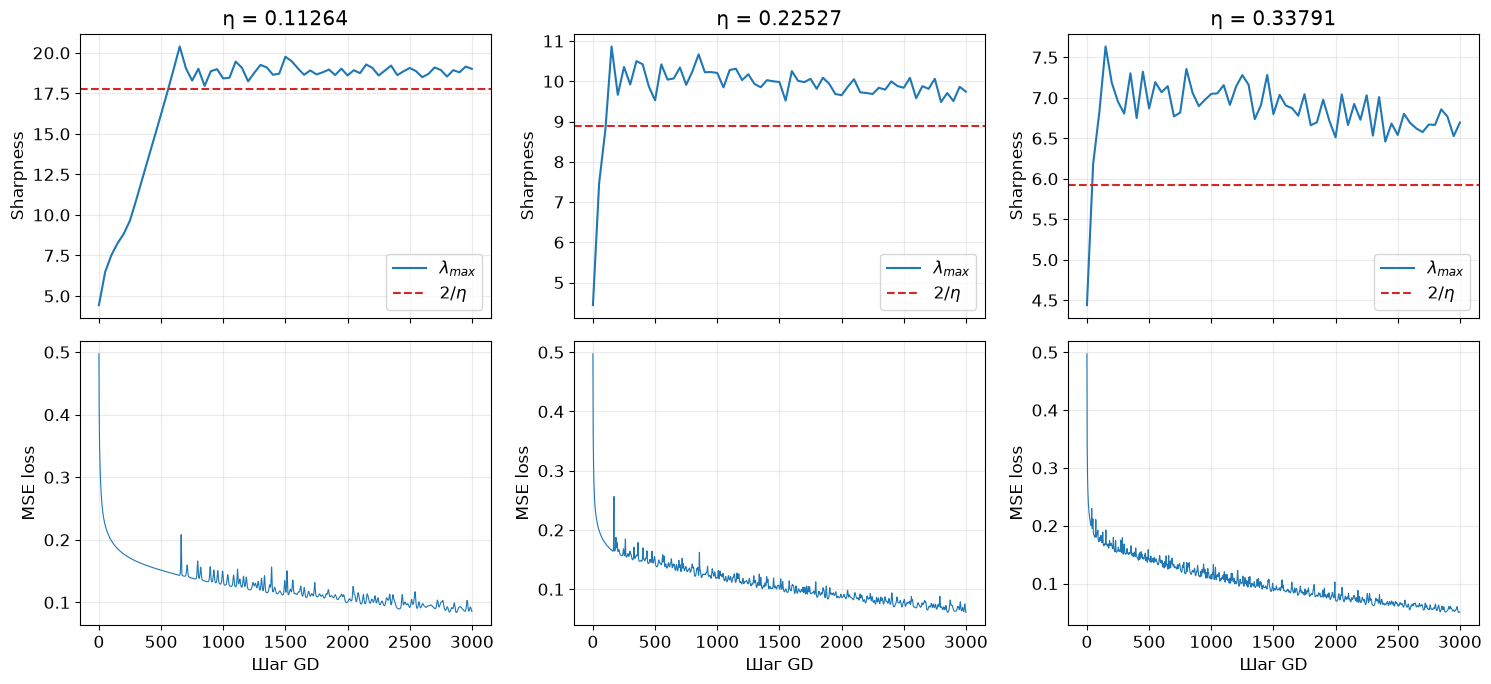

In [93]:
if '7.1' in BONUS_TASKS:
    fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
    for col, (lr, hist) in enumerate(eos_history.items()):
        axes[0, col].plot(hist['sharpness_steps'], hist['sharpness'], label=r'$\lambda_{max}$')
        axes[0, col].axhline(2 / lr, color='tab:red', linestyle='--', label=r'$2/\eta$')
        axes[0, col].set_title(f'η = {lr:.5f}')
        axes[0, col].set_ylabel('Sharpness')
        axes[0, col].legend()
        axes[1, col].plot(hist['loss'], linewidth=0.8)
        axes[1, col].set_ylabel('MSE loss')
        axes[1, col].set_xlabel('Шаг GD')
        for ax in axes[:, col]:
            ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

Ответ: Sharpness вышла на границу во всех трёх прогонах ($\eta\lambda_0=0.5$, 1 и 1.5): после роста с 4.44 она держится немного выше $2/\eta$, и на шаге 3000 отношение $\lambda_{\max}/(2/\eta)$ равно 1.07, 1.10 и 1.13 при границах 17.76, 8.88 и 5.92. До выхода на границу loss убывал монотонно: по истории в `bonus_metrics.json` первый рост приходится на шаги 648, 162 и 34, то есть на интервал между замерами, где это отношение переходит через 1; дальше loss растёт на 1098, 1399 и 1465 шагах из 3000, но в целом снижается с 0.497 до 0.086, 0.061 и 0.051. У квадратичной функции гессиан постоянен, поэтому $\eta<2/\lambda_{\max}$ гарантирует устойчивость на всей траектории; у tanh-сети гессиан меняется вместе с весами, превышение $2/\eta$ раскачивает только верхнее собственное направление, а колебания вдоль него сдвигают веса в область с меньшей кривизной, поэтому sharpness перестаёт расти, а loss не расходится. Вывод получен для одного seed и 2000 изображений, sharpness измерялась раз в 50 шагов 20 итерациями Lanczos; Ritz value не превышает истинного $\lambda_{\max}$, так что выход за $2/\eta$ не объясняется ошибкой solver'а.

## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [94]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x, weight, bias=None, stride=1, padding=0, groups=1):
        n, c_in, _, _ = x.shape
        c_out, _, kh, kw = weight.shape
        x_pad = F.pad(x, (padding, padding, padding, padding))
        hp, wp = x_pad.shape[-2:]
        fft_shape = (hp + kh - 1, wp + kw - 1)

        x_grouped = x_pad.reshape(n, groups, c_in // groups, hp, wp)
        w_grouped = weight.flip(-2, -1).reshape(
            groups, c_out // groups, c_in // groups, kh, kw)
        x_fft = torch.fft.rfft2(x_grouped, s=fft_shape)
        w_fft = torch.fft.rfft2(w_grouped, s=fft_shape)
        out_fft = torch.einsum('ngchw,gfchw->ngfhw', x_fft, w_fft)

        full = torch.fft.irfft2(out_fft, s=fft_shape)
        valid = full[..., kh - 1:hp:stride, kw - 1:wp:stride]
        out = valid.reshape(n, c_out, *valid.shape[-2:])
        if bias is not None:
            out = out + bias.reshape(1, c_out, 1, 1)
        return out


Дополняем вход нулями, переворачиваем ядра и считаем спектры отдельно по группам. После обратного FFT оставляем valid-область и берём каждый `stride`-й элемент.

In [95]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

Дополнительно проверяем `float64`, прямоугольное ядро, две группы и вход после `transpose`, без bias.

In [96]:
if '7.2' in BONUS_TASKS:
    fft_gen = torch.Generator().manual_seed(2)
    fft_x = torch.randn(1, 4, 8, 11, generator=fft_gen,
                        dtype=torch.float64).transpose(-2, -1)
    fft_w = torch.randn(8, 2, 3, 5, generator=fft_gen, dtype=torch.float64)
    fft_out = conv2d_fft(fft_x, fft_w, stride=2, padding=1, groups=2)
    fft_ref = F.conv2d(fft_x, fft_w, stride=2, padding=1, groups=2)
    fft_error = (fft_out - fft_ref).abs().max().item()
    assert torch.allclose(fft_out, fft_ref, atol=1e-12, rtol=1e-12)
    print(f'Исходные проверки: {n_checked}; дополнительная: пройдена')
    print(f'Форма: {tuple(fft_out.shape)}, максимальная ошибка: {fft_error:.2e}')


Исходные проверки: 81; дополнительная: пройдена
Форма: (1, 8, 6, 3), максимальная ошибка: 3.55e-15


**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?

Ответ: При stride $s$ сохраняем примерно $1/s^2$ valid-выходов, то есть выбрасываем $1-1/s^2$: около 75% при $s=2$ и 89% при $s=3$. Для valid-карты $H_v\times W_v$ точная доля равна $1-\lceil H_v/s\rceil\lceil W_v/s\rceil/(H_vW_v)$. Ещё до прореживания отбрасываем края полной FFT-свёртки.

FFT может выиграть на больших ядрах и картах при небольшом stride: прямая свёртка считает все $k_hk_w$ произведений для каждого выхода. На малых ядрах затраты на преобразования и комплексные операции могут оказаться выше; большой stride тоже уменьшает выгоду, поскольку FFT сначала считает полную карту.

## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [97]:
if '7.3' in BONUS_TASKS:
    def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
        # ваш код
        raise NotImplementedError


    class ConvMuon(torch.optim.Optimizer):
        def __init__(self, params, lr=0.02, momentum=0.95):
            super().__init__(params, dict(lr=lr, momentum=momentum))

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                mu = group['momentum']
                for p in group['params']:
                    if p.grad is None:
                        continue
                    # ваш код
                    raise NotImplementedError

In [98]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape)   # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)

In [99]:
if '7.3' in BONUS_TASKS:
    MUON_LR = 0.02
    # ваш код
    raise NotImplementedError
    hist_adamw = history_cifar
    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name, hist in [('AdamW', hist_adamw), ('Muon', hist_muon)]:
        print(f'{name:<10}{hist["train_loss"][-1]:>12.4f}{hist["test_acc"][-1]:>10.4f}')

In [100]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

Ответ: Бонус 7.3 не выбран. Задачи 7.1, 7.2, 7.4 и 7.5 суммарно дают максимальные 4 бонусных балла.

## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [101]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

Атакуем первые 500 тестовых изображений. Сначала проверяем ограничение на число изменённых пикселей, затем сравниваем accuracy двух моделей при одинаковых k.

In [102]:
if '7.4' in BONUS_TASKS:
    l0_started = time.perf_counter()

In [103]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

{'clean': 0.914, 'L0, k=5': 0.664}
standard    0.914  0.894  0.844  0.790  0.664  0.398  0.172  0.044
PGD-AT      0.846  0.808  0.788  0.774  0.730  0.664  0.466  0.326


In [104]:
if '7.4' in BONUS_TASKS:
    RUN_TIMES['bonus_l0_seconds'] = time.perf_counter() - l0_started

In [105]:
if '7.4' in BONUS_TASKS:
    l0_summary = {}
    print(f'{"model":<10}{"k":>5}{"accuracy":>11}{"drop, pp":>11}')
    for name, accs in l0_curves.items():
        l0_summary[name] = {}
        for k in [5, 10, 30]:
            acc = accs[ks.index(k)]
            drop = 100 * (accs[0] - acc)
            l0_summary[name][k] = dict(accuracy=acc, drop_pp=drop)
            print(f'{name:<10}{k:>5}{acc:>11.3f}{drop:>11.1f}')
    print(f'Время L0-эксперимента: {RUN_TIMES["bonus_l0_seconds"]:.1f} с.')

model         k   accuracy   drop, pp
standard      5      0.664       25.0
standard     10      0.398       51.6
standard     30      0.044       87.0
PGD-AT        5      0.730       11.6
PGD-AT       10      0.664       18.2
PGD-AT       30      0.326       52.0
Время L0-эксперимента: 2.2 с.


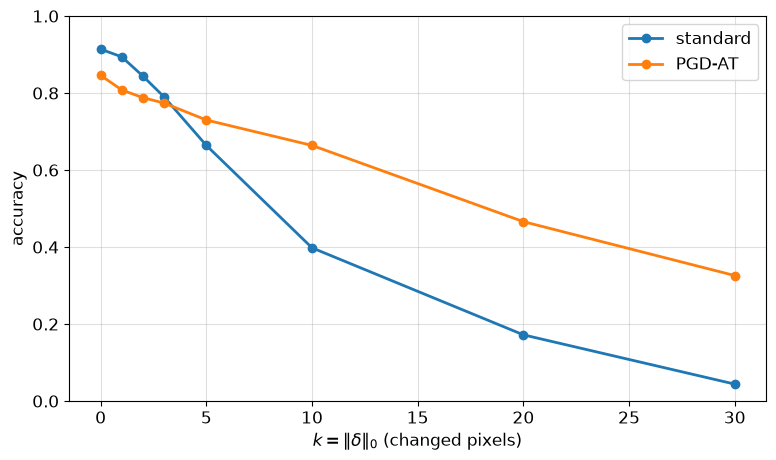

In [106]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

Ответ: Частично помогает. При $k\le3$ стандартная модель ещё впереди за счёт более высокой clean accuracy (91.4% против 84.6%; при $k=3$ 79.0% против 77.4%), а начиная с $k=5$ точнее PGD-AT: 73.0% против 66.4% при $k=5$, 66.4% против 39.8% при $k=10$ и 32.6% против 4.4% при $k=30$, то есть она теряет 11.6, 18.2 и 52.0 п.п. против 25.0, 51.6 и 87.0 п.п., но 30 пикселей из 784 всё равно снижают её accuracy более чем вдвое. Изменение одного пикселя с 0 до 1 имеет $L_\infty$-норму 1, в 10 раз больше радиуса обучения $\varepsilon=0.1$: такое возмущение лежит вне шара, на котором обучали модель, и PGD-AT не даёт для него гарантий; частичный выигрыш, вероятно, связан с меньшей долей градиента на фоне у PGD-AT (21.6% против 56.8% в 6.3). Оценка получена жадной линеаризованной атакой на 500 изображениях, поэтому это верхняя граница $L_0$-робастности: более сильная атака может опустить обе кривые и сократить разрыв.

## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

Обучаем FGSM и FGSM-RS по 5 эпох на 60 000 изображениях, ε=0.2 и seed=0. После каждой эпохи измеряем clean, FGSM и PGD-20 accuracy на первых 1000 тестовых примерах. Для FAST_MODE остаётся сокращённый протокол из задания.

In [107]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_started = time.perf_counter()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])
        RUN_TIMES[f'bonus_co_{name}_seconds'] = time.perf_counter() - co_started

FGSM
Эпоха 1/5: loss = 1.1894, clean = 0.700, FGSM = 0.650, PGD-20 = 0.037
Эпоха 2/5: loss = 0.7529, clean = 0.468, FGSM = 0.897, PGD-20 = 0.002
Эпоха 3/5: loss = 0.1846, clean = 0.398, FGSM = 0.963, PGD-20 = 0.001
Эпоха 4/5: loss = 0.0862, clean = 0.295, FGSM = 0.987, PGD-20 = 0.000
Эпоха 5/5: loss = 0.0534, clean = 0.299, FGSM = 0.988, PGD-20 = 0.000
FGSM-RS
Эпоха 1/5: loss = 1.1918, clean = 0.740, FGSM = 0.585, PGD-20 = 0.334
Эпоха 2/5: loss = 0.8946, clean = 0.775, FGSM = 0.647, PGD-20 = 0.451
Эпоха 3/5: loss = 0.7793, clean = 0.787, FGSM = 0.699, PGD-20 = 0.455
Эпоха 4/5: loss = 0.7083, clean = 0.801, FGSM = 0.729, PGD-20 = 0.462
Эпоха 5/5: loss = 0.6573, clean = 0.801, FGSM = 0.744, PGD-20 = 0.485


In [108]:
if '7.5' in BONUS_TASKS:
    co_summary = {}
    for name, hist in co_history.items():
        pgd_values = np.asarray(hist['pgd'])
        drops = pgd_values[:-1] - pgd_values[1:]
        i = int(np.argmax(drops)) if drops.size else 0
        largest_drop = max(0.0, float(drops[i])) if drops.size else 0.0
        co_summary[name] = dict(
            largest_pgd_drop_pp=100 * largest_drop if drops.size else None,
            from_epoch=i + 1 if largest_drop > 0 else None,
            to_epoch=i + 2 if largest_drop > 0 else None,
            final_clean=hist['clean'][-1],
            final_fgsm=hist['fgsm'][-1],
            final_pgd=hist['pgd'][-1],
            final_fgsm_pgd_gap_pp=100 * (hist['fgsm'][-1] - hist['pgd'][-1]),
        )
        if not drops.size:
            print(f'{name}: для сравнения соседних эпох нужны хотя бы две эпохи.')
        elif largest_drop > 0:
            co_summary[name].update(
                pgd_before=hist['pgd'][i], pgd_after=hist['pgd'][i + 1],
                fgsm_before=hist['fgsm'][i], fgsm_after=hist['fgsm'][i + 1],
            )
            print(f'{name}: наибольший спад PGD-20 на переходе {i + 1} → {i + 2}: '
                  f'{100 * largest_drop:.1f} п.п. '
                  f'({hist["pgd"][i]:.3f} → {hist["pgd"][i + 1]:.3f}); '
                  f'FGSM: {hist["fgsm"][i]:.3f} → {hist["fgsm"][i + 1]:.3f}.')
        else:
            print(f'{name}: PGD-20 accuracy не снижалась между соседними эпохами.')
        print(f'Обучение и проверки по эпохам: {RUN_TIMES[f"bonus_co_{name}_seconds"]:.1f} с.')

FGSM: наибольший спад PGD-20 на переходе 1 → 2: 3.5 п.п. (0.037 → 0.002); FGSM: 0.650 → 0.897.
Обучение и проверки по эпохам: 25.3 с.
FGSM-RS: PGD-20 accuracy не снижалась между соседними эпохами.
Обучение и проверки по эпохам: 25.3 с.


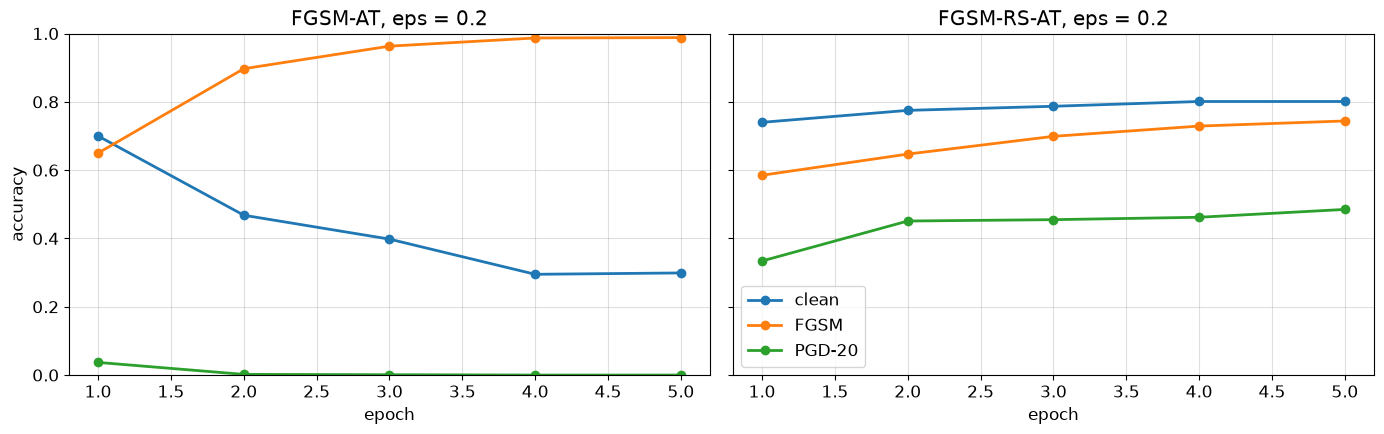

In [109]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

Проверяем финальные модели на первых 256 примерах: PGD-100 с пятью стартами и атака при ε=1. В этой таблице все атаки используют одну выборку, а clean-ошибки тоже считаются ошибками.

In [110]:
if '7.5' in BONUS_TASKS:
    co_checks_started = time.perf_counter()
    torch.manual_seed(0)
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)
    RUN_TIMES['bonus_co_sanity_seconds'] = time.perf_counter() - co_checks_started

{'FGSM': {'fgsm': 0.2578125, 'pgd20': 0.0, 'pgd100_x5': 0.0, 'eps_1': 0.0}, 'FGSM-RS': {'fgsm': 0.74609375, 'pgd20': 0.50390625, 'pgd100_x5': 0.43359375, 'eps_1': 0.0}}


In [111]:
if '7.5' in BONUS_TASKS:
    print(f'{"model":<10}{"FGSM":>10}{"PGD-20":>10}{"PGD-100×5":>12}{"eps=1":>10}')
    for name, values in co_checks.items():
        print(f'{name:<10}{values["fgsm"]:>10.3f}{values["pgd20"]:>10.3f}'
              f'{values["pgd100_x5"]:>12.3f}{values["eps_1"]:>10.3f}')
        co_summary[name]['sanity_pgd20_minus_pgd100_x5_pp'] = (
            100 * (values['pgd20'] - values['pgd100_x5'])
        )
    print(f'Усиленные проверки: {RUN_TIMES["bonus_co_sanity_seconds"]:.1f} с.')

model           FGSM    PGD-20   PGD-100×5     eps=1
FGSM           0.258     0.000       0.000     0.000
FGSM-RS        0.746     0.504       0.434     0.000
Усиленные проверки: 7.3 с.


**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

Ответ: Резкого спада PGD-20 accuracy между замерами нет, потому что у FGSM она почти нулевая уже после первой эпохи: 3.7% против 33.4% у FGSM-RS с тем же seed; наибольший спад, 3.5 п.п. (до 0.2%), приходится на переход 1 → 2, к пятой эпохе остаётся 0%. На том же переходе FGSM accuracy выросла с 65.0% до 89.7%, а clean упала с 70.0% до 46.8%, к пятой эпохе стало 98.8% против 29.9%: шаг FGSM уже исправляет ответы, а PGD находит ошибку почти везде, то есть это catastrophic overfitting с почти нулевой PGD-20 с первой эпохи и FGSM accuracy выше clean со второй. Random start картину изменил: у FGSM-RS PGD-20 accuracy росла каждую эпоху с 33.4% до 48.5% при clean 80.1%, а разрыв FGSM–PGD в конце равен 25.9 п.п. против 98.8 п.п. у FGSM. Усиленная проверка на 256 примерах, где clean-ошибки считаются ошибками (поэтому FGSM у FGSM-модели там 25.8%), это подтверждает: PGD-100 с пятью стартами даёт 0% у FGSM и 43.4% у FGSM-RS, на 7.0 п.п. ниже её PGD-20, а при $\varepsilon=1$ обе модели дают 0%; вывод сделан для одного seed, $\varepsilon=0.2$ и пяти эпох, и момент срыва внутри первой эпохи по замерам раз в эпоху не определить.

Сохраняем результаты выбранных бонусов и веса двух моделей из 7.5. Время ниже относится к вычислениям при полном запуске блокнота.

In [112]:
bonus_metrics = dict(selected=sorted(BONUS_TASKS), points=4.0, results={})
if '7.1' in BONUS_TASKS:
    bonus_metrics['results']['7.1'] = dict(config=eos_config, history=eos_history, summary=eos_summary)
if '7.2' in BONUS_TASKS:
    bonus_metrics['results']['7.2'] = dict(open_tests=n_checked, extra_max_error=fft_error)
if '7.4' in BONUS_TASKS:
    bonus_metrics['results']['7.4'] = dict(n_test=500, k=ks, accuracy=l0_curves, summary=l0_summary)
if '7.5' in BONUS_TASKS:
    bonus_metrics['results']['7.5'] = dict(eps=EPS_CO, epochs=AT_EPOCHS, seed=0,
                                        history=co_history, summary=co_summary, sanity=co_checks)
    for name in ['FGSM', 'FGSM-RS']:
        state = {k: v.detach().cpu() for k, v in robust[f'{name}, eps={EPS_CO}'].state_dict().items()}
        torch.save(state, artifact_dir / f'fashion_co_{name.lower().replace("-", "_")}.pt')
RUN_TIMES['notebook_seconds'] = time.perf_counter() - NOTEBOOK_STARTED
bonus_metrics['timings'] = {k: v for k, v in RUN_TIMES.items() if k.startswith('bonus')}
(artifact_dir / 'bonus_metrics.json').write_text(
    json.dumps(json_ready(bonus_metrics), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8',
)
metrics['bonuses'] = dict(selected=sorted(BONUS_TASKS), points=4.0, file='bonus_metrics.json')
metrics['timings'] = RUN_TIMES
(artifact_dir / 'metrics.json').write_text(
    json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8',
)
print(f"Время вычислений блокнота: {RUN_TIMES['notebook_seconds'] / 60:.2f} мин.")
print('Метрики бонусов: artifacts/bonus_metrics.json')

Время вычислений блокнота: 12.00 мин.
Метрики бонусов: artifacts/bonus_metrics.json
